# Venues within a 30-minute transit trip: H3 hex grid with r5py

The transit companion to `03_hex_walk_access_osmnx.ipynb` (same boundary, H3 resolution, venues and walking speed), sampled and aggregated the same way as `01_otp_isochrones.py`.

**Sampling.** The same four categories, dates and time periods as the OTP script. Each sample is one r5py run over a 30-minute departure window starting at the sample time (median trip time across every departure minute in it), and the samples in each period join up end to end. OTP can only test single departure minutes, so this covers each period more completely than 01 does. Each sample runs from every hex centre to every venue, with walking to and from stops, waits and transfers included. Trips that are fastest on foot count too.

**Aggregation (per hex–venue pair), mirroring the OTP method:**
1. **Per category:** the reachability fraction is the share of that category's samples in which the venue is reached within 30 minutes. A failed or unreachable sample counts as not reached.
2. **Pooled outputs** (`peak_all`, `offpeak_all`, `overall_typical`) average their source categories' fractions with **equal weight**. A category sampled more densely doesn't get more say.
3. **Threshold:** a venue counts as reachable from a hex if its fraction is ≥ `THRESHOLD` (0.5 = "typical"; 0.0 behaves like union, 1.0 like intersection).
4. `venues_reachable_<output>` = number of venues reachable from that hex under that output. `venues_reachable` = the `overall_typical` count, so the app layer reads it the same way as the walk layer.

---

| | |
|---|---|
| **Inputs** | `src/data/geo/toronto-boundary.geo.json` -- feature with `layer` = `toronto-outline`<br>`data/venues/tac-list/current_toronto_arts_locations_eddit.csv` -- all arts locations<br>`analysis/mobility/graphs/toronto/Toronto.osm.pbf`, `TTC-GTFS.zip`, `GO-GTFS.zip`, `UP-GTFS.zip` |
| **Intermediate** | `data/mobility/r5-hex-samples/*.parquet` -- one travel-time matrix per sample (git-ignore it). Finished samples are skipped on re-run, so an interrupted run resumes where it stopped. |
| **Outputs** | **`src/data/mobility/hex_transit_30min_res9.geo.json`** -- H3 res-9 hexes with `venues_reachable` (overall typical) and `venues_reachable_<output>` for all seven outputs |
| **Requirements** | `pip install r5py h3 geopandas pyarrow matplotlib` plus **Java Development Kit 21**. `Graph.obj` is OpenTripPlanner's format and isn't used. |

## 1. Settings

In [1]:
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "package.json").exists())
DATA = ROOT / "data"
SRC_DATA = ROOT / "src" / "data"

BOUNDARY_PATH  = SRC_DATA / "geo" / "toronto-boundary.geo.json"
BOUNDARY_LAYER = "toronto-outline"
VENUES_PATH    = DATA / "venues/tac-list/current_toronto_arts_locations_eddit.csv"

GRAPH_DIR  = ROOT / "analysis" / "mobility" / "graphs" / "toronto"
OSM_PBF    = GRAPH_DIR / "Toronto.osm.pbf"
GTFS_FILES = [GRAPH_DIR / f for f in ("TTC-GTFS.zip", "GO-GTFS.zip", "UP-GTFS.zip")]

SAMPLE_DIR = DATA / "mobility" / "r5-hex-samples"  # per-sample matrices (cache / resume)
OUTPUT_DIR = SRC_DATA / "mobility"

H3_RES         = 9      # identical to the walk notebook
MAX_TRAVEL_MIN = 30
WALK_SPEED_KMH = 4.8    # same as the walk notebook (r5py default is 3.6)
THRESHOLD      = 0.5    # 0.0 = union, 1.0 = intersection, 0.5 = "typical" (same as OTP script)

JAVA_MAX_MEMORY = "8G"

# Each sample tests every departure minute from its start time to DEPARTURE_WINDOW_MIN later
# and keeps the median trip time. Equal to the spacing between sample times, so the
# samples in a period join up end to end with no gaps.
DEPARTURE_WINDOW_MIN = 30

# --- dates and time windows: same periods as 01_otp_isochrones.py ---
# Each time is the START of a DEPARTURE_WINDOW_MIN block, so the last time in each
# 01 list is dropped here: 06:30 ... 09:30 covers 06:30-10:00, the same span as 01.
WEEKDAY_DATES = ["2026-06-10"]   # Wed
WEEKEND_DATES = ["2026-06-13"]   # Sat (TTC weekend service checked in step 3)

WEEKDAY_MORNING_PEAK   = ["06:30", "07:00", "07:30", "08:00", "08:30", "09:00", "09:30"]                    # 06:30-10:00
WEEKDAY_MIDDAY_OFFPEAK = ["11:00", "11:30", "12:00", "12:30", "13:00"]                                      # 11:00-13:30
WEEKDAY_EVENING_PEAK   = ["15:30", "16:00", "16:30", "17:00", "17:30", "18:00", "18:30"]                    # 15:30-19:00
WEEKDAY_NIGHT_OFFPEAK  = ["22:00", "22:30", "23:00"]                                                        # 22:00-23:30

WEEKEND_MORNING_OFFPEAK     = ["07:30", "08:00", "08:30", "09:00"]                                          # 07:30-09:30
WEEKEND_MIDDAY_EVENING_PEAK = ["11:00", "11:30", "12:00", "12:30", "13:00", "13:30", "14:00", "14:30",
                               "15:00", "15:30", "16:00", "16:30", "17:00", "17:30", "18:00", "18:30"]      # 11:00-19:00
WEEKEND_NIGHT_OFFPEAK       = ["21:30", "22:00", "22:30", "23:00"]                                          # 21:30-23:30

CATEGORIES = {
    "weekday_peak":    {"dates": WEEKDAY_DATES, "times": WEEKDAY_MORNING_PEAK + WEEKDAY_EVENING_PEAK},
    "weekday_offpeak": {"dates": WEEKDAY_DATES, "times": WEEKDAY_MIDDAY_OFFPEAK + WEEKDAY_NIGHT_OFFPEAK},
    "weekend_peak":    {"dates": WEEKEND_DATES, "times": WEEKEND_MIDDAY_EVENING_PEAK},
    "weekend_offpeak": {"dates": WEEKEND_DATES, "times": WEEKEND_MORNING_OFFPEAK + WEEKEND_NIGHT_OFFPEAK},
}

COMBINED_OUTPUTS = {
    "peak_all":        ["weekday_peak", "weekend_peak"],
    "offpeak_all":     ["weekday_offpeak", "weekend_offpeak"],
    "overall_typical": ["weekday_peak", "weekday_offpeak", "weekend_peak", "weekend_offpeak"],
}

for p in [BOUNDARY_PATH, VENUES_PATH, OSM_PBF, *GTFS_FILES]:
    assert p.exists(), f"Missing input: {p}"
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

n_total = sum(len(c["dates"]) * len(c["times"]) for c in CATEGORIES.values())
print(f"{n_total} samples across {len(CATEGORIES)} categories")

46 samples across 4 categories


## 2. Imports

The Java memory limit must be set **before** `r5py` is imported.
This cell also finds a JDK 21+ and points `JAVA_HOME` at it, because r5py won't start on an older Java. If a run hangs or fails here, restart the kernel before trying again.

In [2]:
import os
import sys

# r5py needs Java 21 or newer, and it finds Java through JAVA_HOME. On macOS,
# JAVA_HOME is often unset (JPype then crashes with a "not 'bytes'" error) or
# points at an old Java 8 (the JVM rejects r5py's options and the import hangs).
# So look for a real JDK >= 21 and use it, ignoring whatever JAVA_HOME was before.
import glob, re

def java_major(home):
    """Major version of the JDK at `home`, read from its `release` file (None if not a JDK)."""
    try:
        txt = open(os.path.join(home, "release")).read()
    except OSError:
        return None
    m = re.search(r'JAVA_VERSION="(\d+)', txt)
    return int(m.group(1)) if m else None

candidates = {os.environ.get("JAVA_HOME", "")}
for pattern in [
    "/Library/Java/JavaVirtualMachines/*/Contents/Home",
    os.path.expanduser("~/Library/Java/JavaVirtualMachines/*/Contents/Home"),
    "/opt/homebrew/opt/openjdk*/libexec/openjdk.jdk/Contents/Home",   # Homebrew, Apple silicon
    "/usr/local/opt/openjdk*/libexec/openjdk.jdk/Contents/Home",      # Homebrew, Intel
]:
    candidates.update(glob.glob(pattern))

jdks = {h: java_major(h) for h in candidates if h and java_major(h)}
usable = {h: v for h, v in jdks.items() if v >= 21}
if not usable:
    raise RuntimeError(
        f"No JDK 21+ found (found: {jdks or 'none'}). Install one with "
        "`brew install --cask temurin@21` (or from adoptium.net), then restart the kernel."
    )
# Prefer exactly 21 (what r5py is built against), otherwise the newest available.
JAVA_HOME = min(usable, key=lambda h: (usable[h] != 21, -usable[h]))
os.environ["JAVA_HOME"] = JAVA_HOME
os.environ["PATH"] = os.path.join(JAVA_HOME, "bin") + os.pathsep + os.environ["PATH"]
print(f"JAVA_HOME = {JAVA_HOME} (Java {usable[JAVA_HOME]})")

if "--max-memory" not in sys.argv:
    sys.argv.extend(["--max-memory", JAVA_MAX_MEMORY])

import time
import zipfile
import datetime as dt
import numpy as np
import pandas as pd
import geopandas as gpd
import h3
import r5py
from shapely import make_valid, polygonize
from shapely.geometry import Polygon, Point, MultiPolygon

print("r5py", r5py.__version__, "| h3", h3.__version__, "| geopandas", gpd.__version__)

JAVA_HOME = /Library/Java/JavaVirtualMachines/temurin-21.jdk/Contents/Home (Java 21)
r5py 1.1.6 | h3 4.5.0 | geopandas 1.1.3


## 3. Check that every feed actually runs on the sample dates

This counts the trips each feed schedules on each sample date, combining `calendar.txt` (weekday flags within a date range) with `calendar_dates.txt` (added and removed service).
That answers the open question in the OTP script: whether TTC really runs on Saturday 2026-06-13, rather than just whether the date sits inside a range.
A feed showing **0 trips** on a date means every sample on that date would see no service from it.

In [3]:
DAY_COLS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]

def read_gtfs_table(z, names, table):
    return pd.read_csv(z.open(names[table]), dtype=str) if table in names else None

def trips_on_date(path, date_str):
    d = pd.Timestamp(date_str)
    ymd = d.strftime("%Y%m%d")
    with zipfile.ZipFile(path) as z:
        names = {Path(n).name: n for n in z.namelist()}
        cal = read_gtfs_table(z, names, "calendar.txt")
        cd = read_gtfs_table(z, names, "calendar_dates.txt")
        trips = read_gtfs_table(z, names, "trips.txt")
    active = set()
    if cal is not None:
        on = cal[(cal["start_date"] <= ymd) & (cal["end_date"] >= ymd) & (cal[DAY_COLS[d.dayofweek]] == "1")]
        active |= set(on["service_id"])
    if cd is not None:
        today = cd[cd["date"] == ymd]
        active |= set(today.loc[today["exception_type"] == "1", "service_id"])
        active -= set(today.loc[today["exception_type"] == "2", "service_id"])
    return int(trips["service_id"].isin(active).sum())

sample_dates = sorted({d for c in CATEGORIES.values() for d in c["dates"]})
check = pd.DataFrame(
    {p.name: [trips_on_date(p, d) for d in sample_dates] for p in GTFS_FILES},
    index=[f"{d} ({pd.Timestamp(d):%a})" for d in sample_dates],
)
display(check)

zero = [(f, d) for f in check.columns for d in check.index if check.loc[d, f] == 0]
assert not zero, f"No scheduled trips for: {zero}. Pick dates the feeds cover or update the feeds."

,TTC-GTFS.zip,GO-GTFS.zip,UP-GTFS.zip
2026-06-10 (Wed),39880,1753,162
2026-06-13 (Sat),33893,1276,154


## 4. Load the boundary

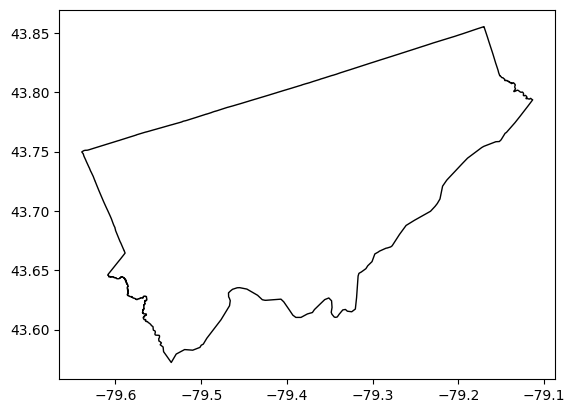

In [4]:
boundary = gpd.read_file(BOUNDARY_PATH).to_crs(4326)
assert "layer" in boundary.columns, f"{BOUNDARY_PATH.name} has no 'layer' property"
boundary = boundary[boundary["layer"] == BOUNDARY_LAYER].copy()
assert len(boundary) > 0, f"No feature with layer == {BOUNDARY_LAYER!r}"

def lines_to_polygon(geom):
    if geom.geom_type in ("LineString", "MultiLineString", "LinearRing"):
        return MultiPolygon(list(polygonize([geom]).geoms))
    return geom

def polygons_only(geom):
    if geom.geom_type in ("Polygon", "MultiPolygon"):
        return geom
    parts = [g for g in getattr(geom, "geoms", []) if g.geom_type in ("Polygon", "MultiPolygon")]
    return MultiPolygon([p for g in parts for p in getattr(g, "geoms", [g])])

boundary["geometry"] = boundary.geometry.apply(lines_to_polygon).apply(make_valid).apply(polygons_only)
boundary_geom = boundary.union_all()
assert boundary_geom.is_valid, "Boundary still invalid after repair"
boundary.plot(edgecolor="black", facecolor="none");

## 5. Build the H3 hex grid

In [5]:
cells = sorted(h3.geo_to_cells(boundary_geom, H3_RES))

def cell_polygon(cell):
    return Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)])

def cell_centroid(cell):
    lat, lng = h3.cell_to_latlng(cell)
    return Point(lng, lat)

hexes = gpd.GeoDataFrame({"id": cells}, geometry=[cell_polygon(c) for c in cells], crs=4326)
hex_points = gpd.GeoDataFrame({"id": cells}, geometry=[cell_centroid(c) for c in cells], crs=4326)
print(f"{len(hexes):,} hexes at resolution {H3_RES}")

5,940 hexes at resolution 9


## 6. Load the venues

Venues outside the boundary are kept. Ids match the walk notebook.

In [6]:
df = pd.read_csv(VENUES_PATH).dropna(subset=["lat", "lon"])
venues = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs=4326)
venues["id"] = [f"v{i}" for i in range(len(venues))]
assert venues["id"].is_unique
print(f"{len(venues):,} venues ({venues.within(boundary_geom).sum():,} inside the boundary)")

2,576 venues (2,576 inside the boundary)


## 7. Build the transport network

Takes a few minutes and several GB of memory.

In [7]:
t0 = time.time()
transport_network = r5py.TransportNetwork(OSM_PBF, GTFS_FILES)
print(f"Network built in {time.time() - t0:.0f} s")

Network built in 2 s


## 8. Run every sample

One matrix per (category, date, time). Each uses a **30-minute departure window** (`DEPARTURE_WINDOW_MIN`): r5py tries every departure minute from the sample time to 30 minutes later and keeps the median trip time, so the samples in a period cover it end to end. Waiting for the first vehicle is part of the trip.
Only pairs reached within `MAX_TRAVEL_MIN` are kept. Each sample is saved as it finishes (written to a `.tmp` file and moved into place with `os.replace`, as in the OTP script's checkpoints, so an interrupted write can't leave a corrupt file); if this cell is interrupted, re-running it skips the samples already on disk.
**If you change dates, times, venues, the boundary or the network, delete `SAMPLE_DIR` first.** (Changing `DEPARTURE_WINDOW_MIN` is handled automatically: it's part of each file name.)

In [ ]:
origins = hex_points[["id", "geometry"]]
destinations = venues[["id", "geometry"]]

def sample_path(cat, date, time_):
    # The window length is part of the file name, so samples made with a different
    # window (e.g. the earlier 1-minute runs) are never reused by mistake.
    return SAMPLE_DIR / f"{cat}_{date}_{time_.replace(':', '')}_w{DEPARTURE_WINDOW_MIN}.parquet"

def save_sample(df, path):
    # Same pattern as save_checkpoint in 01_otp_isochrones.py: write to a
    # .tmp file, then os.replace() it into place. The rename is atomic, so
    # an interrupted write never leaves a half-written .parquet behind that
    # the resume check below would mistake for a finished sample.
    tmp_path = str(path) + ".tmp"
    df.to_parquet(tmp_path, index=False)
    os.replace(tmp_path, path)

# Clean up after earlier runs: leftover .tmp files, and any .parquet that was
# written directly (before the fix above) and is unreadable because a run was
# interrupted mid-write.
for tmp in SAMPLE_DIR.glob("*.parquet.tmp"):
    os.remove(tmp)
for p in SAMPLE_DIR.glob("*.parquet"):
    try:
        pd.read_parquet(p, columns=["from_id"])
    except Exception as e:
        print(f"Removing unreadable sample {p.name} ({e})")
        os.remove(p)

jobs = [(cat, d, t) for cat, cfg in CATEGORIES.items() for d in cfg["dates"] for t in cfg["times"]]
failed = []
for i, (cat, date, time_) in enumerate(jobs, 1):
    path = sample_path(cat, date, time_)
    if os.path.exists(path):
        continue
    t0 = time.time()
    try:
        ttm = r5py.TravelTimeMatrix(
            transport_network,
            origins=origins,
            destinations=destinations,
            departure=dt.datetime.fromisoformat(f"{date}T{time_}"),
            departure_time_window=dt.timedelta(minutes=DEPARTURE_WINDOW_MIN),
            transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
            speed_walking=WALK_SPEED_KMH,
            max_time=dt.timedelta(minutes=MAX_TRAVEL_MIN),
            snap_to_network=True,
        )
    except Exception as e:
        print(f"[{i}/{len(jobs)}] {cat} {date} {time_}: FAILED ({e})")
        failed.append((cat, date, time_))
        continue
    ttm = pd.DataFrame(ttm).dropna(subset=["travel_time"])
    ttm = ttm.loc[ttm["travel_time"] <= MAX_TRAVEL_MIN, ["from_id", "to_id", "travel_time"]]
    save_sample(ttm, path)
    print(f"[{i}/{len(jobs)}] {cat} {date} {time_}: {len(ttm):,} reachable pairs in {time.time() - t0:.0f} s")

done = sum(sample_path(*j).exists() for j in jobs)
print(f"\n{done}/{len(jobs)} samples on disk")
if failed:
    print("Failed (count as unreachable in aggregation; re-run this cell to retry):", failed)

[1/46] weekday_peak 2026-06-10 06:30: 688,223 reachable pairs in 560 s


## 9. Aggregate

Per category: fraction of the category's **nominal** sample count (dates × times) in which each hex–venue pair was reached, as in `threshold_aggregate`. A missing sample counts as not reached.
Pooled outputs: the equal-weighted mean of the source categories' fractions, as in `threshold_aggregate_weighted`. A pair missing from a category contributes 0 for that category.

In [ ]:
def category_fraction(cat):
    cfg = CATEGORIES[cat]
    n_samples = len(cfg["dates"]) * len(cfg["times"])
    parts = [pd.read_parquet(sample_path(cat, d, t), columns=["from_id", "to_id"])
             for d in cfg["dates"] for t in cfg["times"] if sample_path(cat, d, t).exists()]
    if not parts:
        return pd.Series(dtype=float, name=cat)
    hits = pd.concat(parts, ignore_index=True).groupby(["from_id", "to_id"]).size()
    return (hits / n_samples).rename(cat)

fractions = {cat: category_fraction(cat) for cat in CATEGORIES}

def pooled_fraction(sources):
    stacked = pd.concat([fractions[c] for c in sources], axis=1).fillna(0.0)
    return stacked.mean(axis=1)   # equal 1/N weight per source category

all_outputs = {**fractions, **{name: pooled_fraction(src) for name, src in COMBINED_OUTPUTS.items()}}

counts = pd.DataFrame(index=pd.Index(hexes["id"], name="id"))
for name, frac in all_outputs.items():
    reachable = frac[frac >= THRESHOLD].reset_index()
    counts[f"venues_reachable_{name}"] = reachable.groupby("from_id")["to_id"].nunique()
counts = counts.fillna(0).astype(int)
counts["venues_reachable"] = counts["venues_reachable_overall_typical"]

hexes = hexes[["id", "geometry"]].merge(counts.reset_index(), on="id", how="left")
hexes.drop(columns="geometry").describe().T[["mean", "50%", "max"]]

## 10. Compare with the walk layer (optional)

At `THRESHOLD = 0.5`, transit should almost never reach fewer venues than walking alone, since walking is always an allowed mode.
A hex where it does usually means OSMnx and r5py placed the point on the street network differently, not that a real gap exists.

In [ ]:
walk_path = OUTPUT_DIR / f"hex_walk_{MAX_TRAVEL_MIN}min_res{H3_RES}.geo.json"
if walk_path.exists():
    walk = gpd.read_file(walk_path)[["id", "venues_reachable"]].rename(columns={"venues_reachable": "walk"})
    cmp = hexes[["id", "venues_reachable"]].rename(columns={"venues_reachable": "transit"}).merge(walk, on="id")
    print(f"Median venues reachable — walk: {cmp['walk'].median():.0f}, transit (overall typical): {cmp['transit'].median():.0f}")
    print(f"Hexes where transit < walk: {(cmp['transit'] < cmp['walk']).sum():,} of {len(cmp):,}")
else:
    print("No walk output found at", walk_path)

## 11. Summary and map

In [ ]:
cell_area_km2 = h3.average_hexagon_area(H3_RES, unit="km^2")
summary = pd.DataFrame({
    name: hexes[f"venues_reachable_{name}"].describe(percentiles=[0.25, 0.5, 0.75])
    for name in all_outputs
}).T[["mean", "25%", "50%", "75%", "max"]].round(1)
summary["hexes_reaching_0"] = [(hexes[f"venues_reachable_{n}"] == 0).sum() for n in all_outputs]
display(summary)

ax = hexes.plot(column="venues_reachable", cmap="viridis", legend=True, figsize=(9, 9), linewidth=0)
ax.set_title(f"Venues reachable within {MAX_TRAVEL_MIN} min by transit (overall typical, ≥{THRESHOLD:.0%})")
ax.set_axis_off();

## 12. Export

In [ ]:
out_path = OUTPUT_DIR / f"hex_transit_{MAX_TRAVEL_MIN}min_res{H3_RES}.geo.json"
hexes.to_file(out_path, driver="GeoJSON")
print(f"Saved {len(hexes):,} hexes to {out_path.resolve()}")